# 05 — Observational Estimate vs. the Randomized Experiment

**Goal:** demonstrate, hands-on, why an advertiser without a randomized experiment — relying instead on "who happened to see the ad" — can get a biased estimate of incrementality, and why that bias specifically comes from *unobserved* confounders.

The Criteo data used so far is already randomized, so a naive comparison on it is already unbiased (notebook 02). To illustrate the observational-data problem, this notebook **synthetically re-introduces selection bias** by resampling treatment/control from the real data so that `treatment` becomes correlated with feature `f0` (as if, say, higher-`f0` users were more likely to be shown ads in some non-randomized log). We then compare three estimates against the ground truth from notebook 02:

1. **Naive difference-in-means** on the biased sample (expected to be biased).
2. **Propensity-score weighting (IPW)** adjusting for `f0` (the confounder is observed and modeled — bias should mostly disappear).
3. **IPW without `f0`** (the confounder is *unobserved* by the analyst — bias should remain), the core lesson about why observational inference is only as good as the confounders you think to measure.

In [1]:
import sys, warnings
sys.path.append('..')
warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from src.data_loader import load_sample
from src.causal_estimates import compute_itt_lift

df = load_sample()
true_result = compute_itt_lift(df)
true_ate = true_result.absolute_lift
print(f'Ground truth (RCT) absolute lift: {true_ate:.4%}')

Ground truth (RCT) absolute lift: 0.1231%


## Step 1 — construct a synthetically confounded sample

In [2]:
rng = np.random.default_rng(42)

# Keep rows with a probability that depends on f0 and treatment, to induce
# treatment <-> f0 correlation, then stack the kept rows into one biased sample.
f0_z = (df['f0'] - df['f0'].mean()) / df['f0'].std()
keep_prob_treated = 1 / (1 + np.exp(-1.5 * f0_z))      # high f0 -> more likely kept if treated
keep_prob_control = 1 / (1 + np.exp(1.5 * f0_z))       # low f0 -> more likely kept if control

is_treated = df['treatment'] == 1
keep_prob = np.where(is_treated, keep_prob_treated, keep_prob_control)
keep_mask = rng.uniform(size=len(df)) < keep_prob
biased = df[keep_mask].reset_index(drop=True)

print(f'Biased sample size: {len(biased):,} ({len(biased)/len(df):.1%} of original)')
print(biased.groupby('treatment')['f0'].mean())

Biased sample size: 709,232 (50.7% of original)


treatment
0    16.300821
1    22.806218
Name: f0, dtype: float64


As intended, `f0` is now systematically higher in the (synthetic) treatment group than in the control group — exactly the kind of confounding a real non-randomized ad-exposure log could exhibit (e.g. because the ad platform's targeting itself favors certain users).

## Step 2 — naive difference-in-means on the biased sample (expected: biased)

In [3]:
naive_biased_result = compute_itt_lift(biased)
print(f'Naive estimate on biased sample: {naive_biased_result.absolute_lift:.4%}')
print(f'Ground truth (RCT):              {true_ate:.4%}')
print(f'Bias: {naive_biased_result.absolute_lift - true_ate:+.4%}')

Naive estimate on biased sample: -0.1105%
Ground truth (RCT):              0.1231%
Bias: -0.2336%


## Step 3 — propensity-score weighting (IPW), adjusting for the confounder `f0`

Inverse-propensity weighting re-weights each unit by 1/P(received their actual treatment | covariates), which rebalances the weighted sample to look as if treatment had been randomized with respect to the covariates included in the propensity model.

In [4]:
def ipw_ate(data, propensity_features, outcome_col='conversion', treatment_col='treatment'):
    X = data[propensity_features].values
    t = data[treatment_col].values
    y = data[outcome_col].values
    ps_model = LogisticRegression(max_iter=1000)
    ps_model.fit(X, t)
    ps = np.clip(ps_model.predict_proba(X)[:, 1], 0.01, 0.99)
    # Horvitz-Thompson / stabilized IPW estimator of the ATE
    weight_treated = t / ps
    weight_control = (1 - t) / (1 - ps)
    mu1 = np.sum(weight_treated * y) / np.sum(weight_treated)
    mu0 = np.sum(weight_control * y) / np.sum(weight_control)
    return mu1 - mu0

ipw_with_f0 = ipw_ate(biased, propensity_features=['f0'])
print(f'IPW estimate adjusting for f0:   {ipw_with_f0:.4%}')
print(f'Ground truth (RCT):              {true_ate:.4%}')
print(f'Bias: {ipw_with_f0 - true_ate:+.4%}')

IPW estimate adjusting for f0:   0.0797%
Ground truth (RCT):              0.1231%
Bias: -0.0434%


## Step 4 — IPW *without* `f0` (the confounder is unobserved)

Now suppose the analyst never thought to collect/model `f0` — a stand-in for any real-world confounder an analyst doesn't know to measure. We adjust for the other 11 features instead, which are (by construction) unrelated to how we induced the bias.

In [5]:
other_features = [c for c in df.columns if c.startswith('f') and c != 'f0']
ipw_without_f0 = ipw_ate(biased, propensity_features=other_features)
print(f'IPW estimate WITHOUT f0 (unobserved confounder): {ipw_without_f0:.4%}')
print(f'Ground truth (RCT):                              {true_ate:.4%}')
print(f'Bias: {ipw_without_f0 - true_ate:+.4%}')

IPW estimate WITHOUT f0 (unobserved confounder): 0.0561%
Ground truth (RCT):                              0.1231%
Bias: -0.0670%


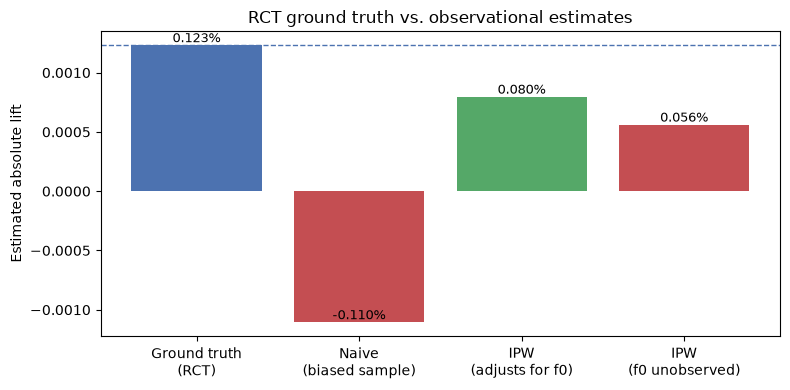

In [6]:
import matplotlib.pyplot as plt

methods = ['Ground truth\n(RCT)', 'Naive\n(biased sample)', 'IPW\n(adjusts for f0)', 'IPW\n(f0 unobserved)']
values = [true_ate, naive_biased_result.absolute_lift, ipw_with_f0, ipw_without_f0]
colors = ['#4C72B0', '#C44E52', '#55A868', '#C44E52']

fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(methods, values, color=colors)
ax.axhline(true_ate, color='#4C72B0', linestyle='--', linewidth=1)
ax.set_ylabel('Estimated absolute lift')
ax.set_title('RCT ground truth vs. observational estimates')
for bar, val in zip(bars, values):
    ax.text(bar.get_x() + bar.get_width() / 2, val, f'{val:.3%}', ha='center', va='bottom', fontsize=9)
plt.tight_layout()
plt.show()

## Conclusion: assumptions, limitations, and when not to trust an observational estimate

- The **naive comparison on the biased sample** is off from the RCT ground truth, because `f0` affects both who got "treated" (by construction here) and the outcome — a textbook confounder.
- **IPW adjusting for `f0`** pulls the estimate back toward the ground truth, because the confounder is observed and explicitly modeled.
- **IPW without `f0`** does **not** fully correct the bias, even though it adjusts for every *other* feature — because propensity-score methods can only balance confounders the analyst actually includes in the model. An unobserved or unmeasured confounder (budget constraints, a sales rep's manual targeting choices, seasonality, anything not in the feature set) will leave residual bias no matter how sophisticated the weighting scheme is.

**When to trust which estimate:** a randomized experiment (notebook 02) is the only one of these that doesn't depend on having measured the right confounders. An observational estimate like IPW should be trusted only when there's a credible argument that *all* material confounders are observed and correctly modeled — a much stronger and harder-to-verify assumption than it often gets credit for in practice.